# Part 1: What is uplift modelling? Your churn model is answering the wrong question

*Series: Who Will Stay Because of Us? Uplift Modelling and Causal Inference for Client Attrition*

**New to churn or attrition modelling?** This series assumes you know what a churn model does. A good primer: [Causal Machine Learning for Customer Retention](https://towardsdatascience.com/causal-machine-learning-for-customer-retention-a-practical-guide-with-python-6bd959b25741/).

**In this notebook**

1. Meet the synthetic bank used throughout the series.
2. See what the bank's churn model tells relationship managers (RMs) to do.
3. Look behind the curtain at something real data never shows: how much a call actually changes each client's chance of leaving.
4. See why the riskiest clients and the clients worth calling are not the same people.

All data is synthetic. See `docs/data_spec.md` for how it is generated.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_series import SERIES_SEED, generate_bank, observed_view
from uplift_series import plotting as P

P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)

## 1. The bank

A bank serves 40,000 institutional clients through RMs. Every cycle, an existing churn model scores every client, and the 6,000 riskiest are sent to RMs.

In this part we use `assignment="random"`: whenever RMs offered a pricing negotiation, it went to a random flagged client. That keeps things simple for now. Act 3 of the series shows what happens when RMs choose for themselves.

In [2]:
df = generate_bank(assignment="random", seed=SERIES_SEED)
seen = observed_view(df)   # what an analyst at the bank can actually see
print(f"{len(df):,} clients, {df['flagged'].sum():,} flagged for RMs")
seen[["client_id", "segment", "revenue_ttm", "tenure_years", "pricing_gap",
      "churn_score", "flagged", "treatment", "churned_6m"]].head()

40,000 clients, 6,000 flagged for RMs


,client_id,segment,revenue_ttm,tenure_years,pricing_gap,churn_score,flagged,treatment,churned_6m
0,C00001,mid_market,789000.000,8.000,-0.046,0.004,0,none,0
1,C00002,commercial,138000.000,4.800,0.084,0.288,1,none,0
2,C00003,large_corporate,12645000.000,7.800,0.002,0.009,0,none,0
3,C00004,commercial,107000.000,3.200,0.027,0.077,0,none,0
4,C00005,large_corporate,1995000.000,15.300,0.003,0.007,0,none,0


## 2. What the churn model tells RMs

The churn model ranks clients by how likely they are to leave. The flagged clients really are risky: they leave several times more often than everyone else.

In [3]:
summary = (
    df.groupby(df["flagged"].map({1: "Flagged for RMs", 0: "Not flagged"}))
      .agg(clients=("client_id", "size"),
           avg_churn_score=("churn_score", "mean"),
           actual_churn_6m=("churned_6m", "mean"))
)
summary

,clients,avg_churn_score,actual_churn_6m
flagged,,,
Flagged for RMs,6000,0.272,0.207
Not flagged,34000,0.048,0.052


The natural instruction to RMs is: **start at the top of the list and work down.** The riskiest clients get called first.

That instruction quietly assumes something: that a call helps the riskiest clients the most. A churn model cannot check that assumption, because it only answers *"Will this client leave?"* It says nothing about *"Will this client stay **because we called**?"*

That second question is what uplift modelling answers:

> **Uplift = P(churn if we do nothing) − P(churn if we act)**

## 3. Behind the curtain: two clients with the same risk

In real life you never see both numbers for the same client, because each client either got the call or did not. Our data is synthetic, so we *can* see both. These are the `true_` columns, the oracle that every later part uses to check its answers.

Below are two flagged clients with almost the same churn risk.

In [4]:
flagged = df[df["flagged"] == 1]
similar_risk = flagged[flagged["true_p_churn_no_action"].between(0.34, 0.36)]

lost = similar_risk[similar_risk["true_client_type"] == "lost_cause"]
client_a = lost.loc[(lost["true_uplift"] - 0.01).abs().idxmin()]
client_b = similar_risk[similar_risk["true_client_type"] == "persuadable"].nlargest(1, "true_uplift").iloc[0]

pair = pd.DataFrame([client_a, client_b], index=["Client A", "Client B"])[
    ["true_p_churn_no_action", "true_p_churn_pricing", "true_uplift",
     "pricing_gap", "corporate_event", "true_client_type"]
]
pair

,true_p_churn_no_action,true_p_churn_pricing,true_uplift,pricing_gap,corporate_event,true_client_type
Client A,0.344,0.335,0.009,0.019,0,lost_cause
Client B,0.354,0.038,0.316,0.103,0,persuadable


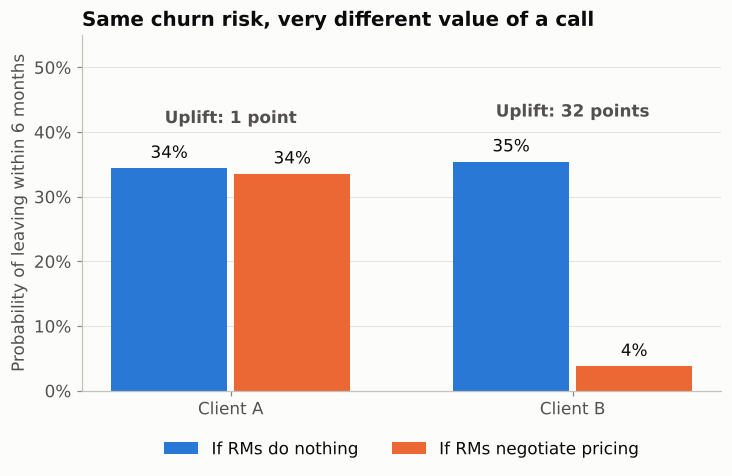

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
names = ["Client A", "Client B"]
no_action = pair["true_p_churn_no_action"].to_numpy()
with_call = pair["true_p_churn_pricing"].to_numpy()
x = np.arange(len(names))
w = 0.34

bars1 = ax.bar(x - w / 2 - 0.01, no_action, w, color=P.BLUE, label="If RMs do nothing")
bars2 = ax.bar(x + w / 2 + 0.01, with_call, w, color=P.ORANGE, label="If RMs negotiate pricing")
for bars in (bars1, bars2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.0%}",
                ha="center", va="bottom", color=P.INK, fontsize=11)

for i, name in enumerate(names):
    drop = no_action[i] - with_call[i]
    ax.text(i, max(no_action[i], with_call[i]) + 0.07, f"Uplift: {drop * 100:.0f} point{'s' if abs(round(drop * 100)) != 1 else ''}",
            ha="center", color=P.INK_SECONDARY, fontsize=11, fontweight="bold")

ax.set_xticks(x, names)
ax.set_ylim(0, 0.55)
P.percent_axis(ax)
ax.set_ylabel("Probability of leaving within 6 months")
ax.set_title("Same churn risk, very different value of a call")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
P.save(fig, "01_same_risk_different_uplift")
plt.show()

Both clients look identical to the churn model: about a 35% chance of leaving. But:

- **Client A** is in the middle of a merger and will consolidate banks. A pricing call barely moves their risk. Calling them is wasted effort.
- **Client B** is paying noticeably more than peers. A pricing negotiation cuts their risk sharply. This is the call that saves a client.

A churn list cannot tell these two apart. An uplift model can.

## 4. Is this just two unlucky examples?

If high risk and high uplift went together, ranking by risk would be fine. Let's check across all 6,000 flagged clients.

Correlation between churn risk and uplift among flagged clients: -0.01


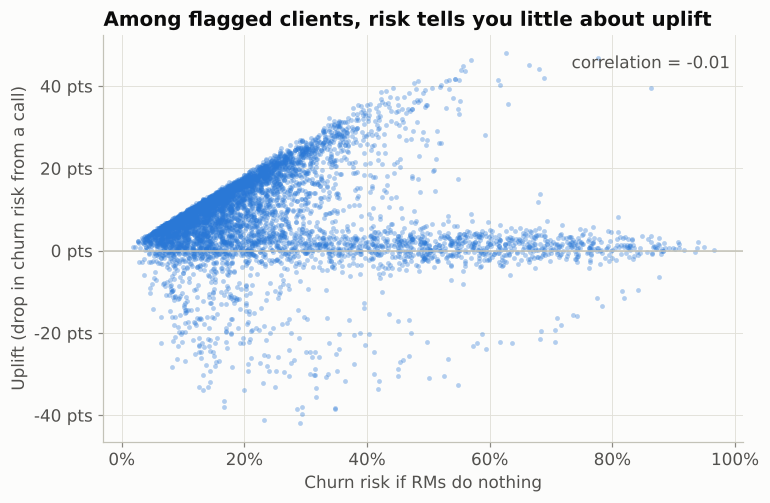

In [6]:
corr = flagged[["true_p_churn_no_action", "true_uplift"]].corr().iloc[0, 1]
print(f"Correlation between churn risk and uplift among flagged clients: {corr:.2f}")

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(flagged["true_p_churn_no_action"], flagged["true_uplift"],
           s=10, color=P.BLUE, alpha=0.35, linewidths=0)
ax.axhline(0, color=P.BASELINE, linewidth=1)
P.percent_axis(ax, "x")
ax.set_xlabel("Churn risk if RMs do nothing")
ax.set_ylabel("Uplift (drop in churn risk from a call)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v * 100:.0f} pts")
ax.set_title("Among flagged clients, risk tells you little about uplift")
ax.text(0.98, 0.95, f"correlation = {corr:.2f}", transform=ax.transAxes,
        ha="right", va="top", color=P.INK_SECONDARY)
P.save(fig, "01_risk_vs_uplift")
plt.show()

Among the clients RMs actually call, churn risk and uplift are essentially unrelated. Points below the zero line are clients for whom a call makes leaving *more* likely. Some of the very riskiest clients gain almost nothing from a call, and a few clients below the zero line are pushed *towards* leaving by being contacted.

## Takeaways

- A churn model answers **"Who will leave?"** A retention budget needs the answer to **"Who will stay because we acted?"**
- That second quantity is **uplift**: churn risk without action minus churn risk with action.
- Two clients with the same risk can have completely different uplift, and across the flagged pool the two are barely related.
- Uplift is never observed for a single real client. The synthetic bank lets us see it, so every later part can check its methods against the truth.

**Next, Part 2:** the four kinds of client hiding inside a churn list, and what happens to the number of clients saved when RMs call the riskiest first.